# 3. Обучение, оценка и улучшение моделей

**Автор:** Шинкарев Сергей Дмитриевич, группа о.ИЗДт 23.2/Б3-22  
**Тема ВКР:** «Разработка системы интеллектуального анализа данных мониторинга вузов»

Блокнот проходит полный путь: опорные модели → базовая нейронная сеть → анализ ошибок → улучшенная архитектура →
подбор гиперпараметров → ансамбль → итоговая оценка → сохранение и загрузка модели → применение.
Все функции берутся из пакета `vuzmon.ml`, которым пользуется и веб-приложение.

In [1]:
# Подключаем пакет проекта: блокнот лежит в каталоге notebooks, код — уровнем выше
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)

from vuzmon import config
import json, torch
from vuzmon.collect.crawler import load_frames
from vuzmon.ml import pipeline, plots, metrics, trainer, registry, explain
from vuzmon.ml.dataset import CLASS_NAMES
from vuzmon.ml.trainer import TrainConfig
from vuzmon.ml.softmax_numpy import SoftmaxRegressionGD
from vuzmon.ml.networks import MonitoringMLP, count_distribution

frames = load_frames(config.MONITORING_DIR)
prepared = pipeline.prepare_data(frames)
print("PyTorch", torch.__version__, "| признаков:", len(prepared.feature_names))
results = {}          # сводная таблица результатов

def remember(name, outcome):
    """Запоминает метрики модели для итогового сравнения."""
    results[name] = {f"{part}: {key}": round(outcome[part][key], 3) for part in ("val", "test")
                     for key in ("accuracy", "macro_f1", "macro_auc", "log_loss")}
    return pd.DataFrame(results).T

remember("Наивный прогноз (класс не изменится)", pipeline.persistence_reports(prepared))

PyTorch 2.2.2 | признаков: 152


,val: accuracy,val: macro_f1,val: macro_auc,val: log_loss,test: accuracy,test: macro_f1,test: macro_auc,test: log_loss
Наивный прогноз (класс не изменится),0.754,0.719,0.791,1.149,0.796,0.778,0.834,0.957


## 3.1. Опорная модель: softmax-регрессия «с нуля»

Многоклассовая логистическая регрессия реализована на NumPy без готовых алгоритмов обучения (`vuzmon/ml/softmax_numpy.py`).

$$z = XW + b,\qquad p_k = \frac{e^{z_k}}{\sum_j e^{z_j}},\qquad
L = -\frac{1}{N}\sum_{i=1}^{N} \ln p_{i,y_i} + \frac{\lambda}{2}\lVert W\rVert^2$$

Градиент функции потерь по логитам равен $P - Y$, поэтому $\partial L/\partial W = X^{\top}(P - Y)/N + \lambda W$.
Параметры обновляются мини-пакетным градиентным спуском с моментом.

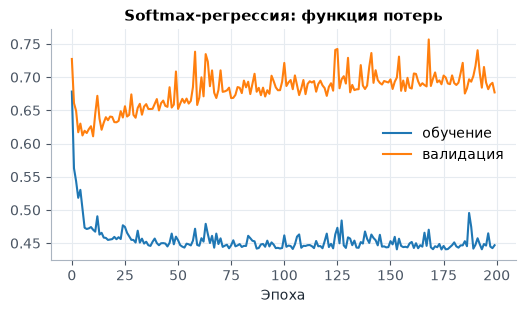

,val: accuracy,val: macro_f1,val: macro_auc,val: log_loss,test: accuracy,test: macro_f1,test: macro_auc,test: log_loss
Наивный прогноз (класс не изменится),0.754,0.719,0.791,1.149,0.796,0.778,0.834,0.957
Softmax-регрессия на NumPy,0.723,0.682,0.871,0.665,0.738,0.724,0.888,0.630


In [2]:
softmax_run = pipeline.run_softmax(prepared, learning_rate=0.05, epochs=200, seed=42)
history = softmax_run["model"].history
plt.figure(figsize=(6, 3)); plt.plot([h["train_loss"] for h in history], label="обучение"); plt.plot([h["val_loss"] for h in history], label="валидация")
plt.title("Softmax-регрессия: функция потерь"); plt.xlabel("Эпоха"); plt.legend(); plt.show()
remember("Softmax-регрессия на NumPy", softmax_run)

## 3.2. Базовая нейронная сеть

Первая версия — обычный многослойный перцептрон 64–32 с одним выходом на три класса, без нормализации и регуляризации,
оптимизатор SGD. Функция потерь — перекрёстная энтропия.

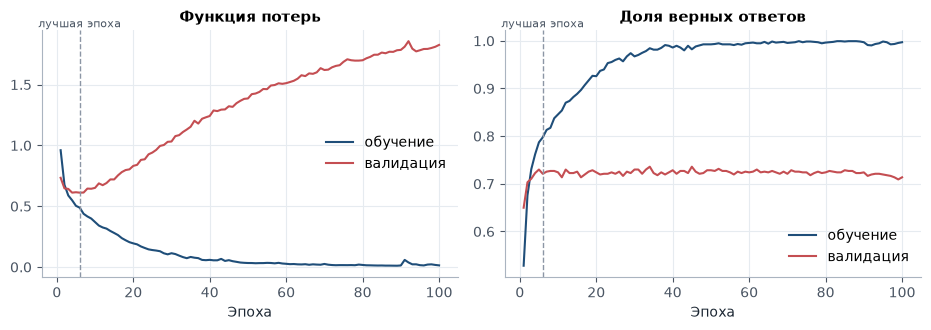

,val: accuracy,val: macro_f1,val: macro_auc,val: log_loss,test: accuracy,test: macro_f1,test: macro_auc,test: log_loss
Наивный прогноз (класс не изменится),0.754,0.719,0.791,1.149,0.796,0.778,0.834,0.957
Softmax-регрессия на NumPy,0.723,0.682,0.871,0.665,0.738,0.724,0.888,0.630
Базовая сеть 64-32 (SGD),0.721,0.677,0.869,0.611,0.757,0.736,0.899,0.537


In [3]:
base_config = TrainConfig(hidden=(64, 32), dropout=0.0, batch_norm=False, optimizer="sgd", learning_rate=0.01,
                          weight_decay=0.0, epochs=100, patience=0, scheduler="none", aux_weight=0.0)
base = pipeline.run_mlp(prepared, base_config)
plots.learning_curves(base["result"].history, base["result"].best_epoch); plt.show()
remember("Базовая сеть 64-32 (SGD)", base)

**Анализ.** Ошибка на валидации перестаёт падать уже через несколько эпох, а на обучении продолжает уменьшаться —
сеть переобучается: объектов немного (1 348), признаков много (152). По доле верных ответов базовая сеть уступает
наивному прогнозу. Нужны регуляризация и архитектура, учитывающая устройство задачи.

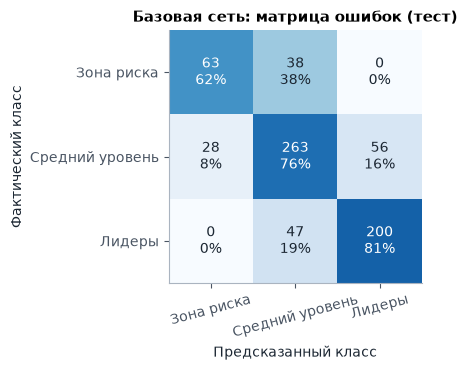

In [4]:
plots.confusion_matrix(base["test"]["confusion_matrix"], CLASS_NAMES, "Базовая сеть: матрица ошибок (тест)"); plt.show()

## 3.3. Улучшение архитектуры: многозадачная сеть

Класс следующего года — это функция числа выполненных показателей. Поэтому сети даётся **вспомогательная задача**:
предсказать для каждого из пяти показателей, будет ли он не ниже медианы. Общая функция потерь:

$$L = \mathrm{CE}(\text{класс}) + \lambda_{aux}\cdot \mathrm{BCE}(\text{выполнение показателей})$$

По пяти вероятностям $q_1..q_5$ распределение числа выполненных показателей вычисляется свёрткой
(распределение Пуассона — биномиальное), затем сворачивается в вероятности классов. Итоговый ответ —
взвешенная сумма этой «структурной» оценки и softmax основного выхода. Добавлены пакетная нормализация,
прореживание (dropout), оптимизатор AdamW, уменьшение шага при остановке роста и ранняя остановка.

In [5]:
# Проверка свёртки на простом примере: два показателя с вероятностями 0.2 и 0.9
print(count_distribution(torch.tensor([[0.2, 0.9]])).numpy().round(3), "- вероятности того, что выполнено 0, 1, 2 показателя")
model = MonitoringMLP(len(prepared.feature_names), 3, (128, 64), dropout=0.3, n_aux=5)
print(model)
print("Обучаемых параметров:", model.count_parameters())

[[0.08 0.74 0.18]] - вероятности того, что выполнено 0, 1, 2 показателя
MonitoringMLP(
  (body): Sequential(
    (0): Linear(in_features=152, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
  )
  (head): Linear(in_features=64, out_features=3, bias=True)
  (aux_head): Linear(in_features=64, out_features=5, bias=True)
)
Обучаемых параметров: 28744


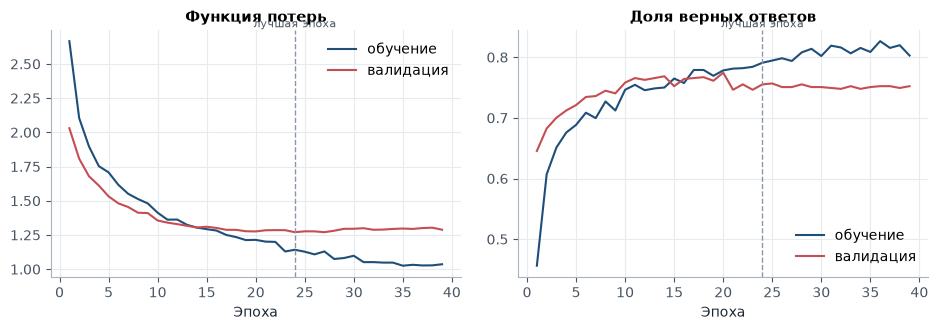

,val: accuracy,val: macro_f1,val: macro_auc,val: log_loss,test: accuracy,test: macro_f1,test: macro_auc,test: log_loss
Наивный прогноз (класс не изменится),0.754,0.719,0.791,1.149,0.796,0.778,0.834,0.957
Softmax-регрессия на NumPy,0.723,0.682,0.871,0.665,0.738,0.724,0.888,0.630
Базовая сеть 64-32 (SGD),0.721,0.677,0.869,0.611,0.757,0.736,0.899,0.537
"Сеть 128-64 с регуляризацией, один выход",0.730,0.676,0.872,0.596,0.768,0.748,0.911,0.515
Многозадачная сеть 128-64,0.755,0.717,0.890,0.560,0.799,0.783,0.920,0.494


In [6]:
single_task = pipeline.run_mlp(prepared, TrainConfig(aux_weight=0.0))
remember("Сеть 128-64 с регуляризацией, один выход", single_task)
multi_task = pipeline.run_mlp(prepared, TrainConfig())
plots.learning_curves(multi_task["result"].history, multi_task["result"].best_epoch); plt.show()
remember("Многозадачная сеть 128-64", multi_task)

## 3.4. Подбор гиперпараметров

Случайный поиск по сетке: размеры слоёв, dropout, шаг обучения, L2-регуляризация, размер пакета, сглаживание меток,
функция активации, вес вспомогательной задачи, доля структурной оценки. Качество измеряется **на валидации**;
тестовая выборка в подборе не участвует. Полный подбор (30 испытаний) выполнен командой `python -m vuzmon.ml`,
его протокол сохранён в `models/metrics.json`; здесь для наглядности выполняется короткий поиск из 8 испытаний.

In [7]:
trials = pipeline.random_search(prepared, n_trials=8, seed=7)
pd.DataFrame([{**{k: t["params"][k] for k in ("hidden", "dropout", "learning_rate", "weight_decay", "batch_size", "aux_weight", "structure_weight")},
               "лучшая эпоха": t["best_epoch"], "верных (вал.)": round(t["val_accuracy"], 3), "macro-F1 (вал.)": round(t["val_macro_f1"], 3)} for t in trials])

,hidden,dropout,learning_rate,weight_decay,batch_size,aux_weight,structure_weight,лучшая эпоха,верных (вал.),macro-F1 (вал.)
0,"[128, 64, 32]",0.1,0.0030,0.00100,32,2.0,0.75,5,0.760,0.720
1,"[256, 128]",0.5,0.0010,0.00010,64,2.0,0.75,26,0.757,0.716
2,"[128, 64, 32]",0.4,0.0010,0.01000,64,3.0,1.00,60,0.761,0.715
3,"[128, 64, 32]",0.3,0.0010,0.00010,32,2.0,0.75,38,0.755,0.712
4,"[128, 64]",0.1,0.0010,0.01000,64,0.0,0.75,16,0.754,0.712
5,"[256, 128, 64]",0.3,0.0003,0.00010,32,1.0,0.50,51,0.751,0.706
6,"[256, 128, 64]",0.5,0.0010,0.00001,128,2.0,0.50,59,0.740,0.701
7,"[256, 128, 64]",0.1,0.0010,0.01000,64,0.0,1.00,5,0.727,0.678


In [8]:
summary = json.loads((config.MODELS_DIR / "metrics.json").read_text(encoding="utf-8"))
full = pd.DataFrame([{**{k: t["params"][k] for k in ("hidden", "dropout", "learning_rate", "weight_decay", "aux_weight", "structure_weight")},
                      "macro-F1 (вал.)": round(t["val_macro_f1"], 3), "верных (вал.)": round(t["val_accuracy"], 3)} for t in summary["trials"]])
print("Полный подбор: испытаний —", len(full), "| лучшие пять конфигураций:")
display(full.head(5))
# Влияние веса вспомогательной задачи на качество (по всем 30 испытаниям)
full.groupby("aux_weight")["macro-F1 (вал.)"].agg(["mean", "max", "count"]).round(3).rename(columns={"mean": "среднее", "max": "лучшее", "count": "испытаний"})

Полный подбор: испытаний — 30 | лучшие пять конфигураций:


,hidden,dropout,learning_rate,weight_decay,aux_weight,structure_weight,macro-F1 (вал.),верных (вал.)
0,"[256, 128]",0.1,0.0030,0.01000,3.0,1.0,0.737,0.773
1,"[256, 128]",0.4,0.0010,0.01000,1.0,0.5,0.731,0.764
2,"[128, 64, 32]",0.2,0.0010,0.00010,2.0,1.0,0.730,0.766
3,"[256, 128, 64]",0.3,0.0010,0.00010,2.0,0.5,0.726,0.758
4,"[128, 64]",0.1,0.0003,0.00001,2.0,0.5,0.722,0.760


,среднее,лучшее,испытаний
aux_weight,,,
0.0,0.704,0.719,7
1.0,0.719,0.731,5
2.0,0.717,0.730,10
3.0,0.714,0.737,8


## 3.5. Итоговая модель: ансамбль сетей

Различия между испытаниями сопоставимы со случайным разбросом (валидационная выборка — 674 объекта), поэтому
лучшая конфигурация обучается пять раз с разными начальными весами, а вероятности усредняются. Итоговая модель
сохранена в файле `models/model1.pt`. Ниже она загружается из файла и проверяется на тестовом годе.

In [9]:
loaded = registry.load_model(config.MODELS_DIR / "model1.pt")
print("Автор:", loaded.meta["author"], "|", loaded.meta["topic"])
print("Сетей в ансамбле:", len(loaded.model.members), "| параметров:", loaded.model.count_parameters())
print("Гиперпараметры:", {k: v for k, v in loaded.meta["train_config"].items() if k in ("hidden", "dropout", "learning_rate", "weight_decay", "aux_weight", "structure_weight", "ensemble_size")})

def predict(x):
    return trainer.predict_proba(loaded.model, x)

final = pipeline.evaluate(predict, prepared)
print("Доля верных ответов на тесте (пересчёт):", round(final["test"]["accuracy"], 4),
      "| записано в файле модели:", round(loaded.meta["metrics"]["test"]["accuracy"], 4))
remember("Ансамбль многозадачных сетей (model1.pt)", final)

Автор: Шинкарев Сергей Дмитриевич | Разработка системы интеллектуального анализа данных мониторинга вузов
Сетей в ансамбле: 5 | параметров: 369320
Гиперпараметры: {'hidden': [256, 128], 'dropout': 0.1, 'learning_rate': 0.003, 'weight_decay': 0.01, 'aux_weight': 3.0, 'structure_weight': 1.0, 'ensemble_size': 5}
Доля верных ответов на тесте (пересчёт): 0.7885 | записано в файле модели: 0.7885


,val: accuracy,val: macro_f1,val: macro_auc,val: log_loss,test: accuracy,test: macro_f1,test: macro_auc,test: log_loss
Наивный прогноз (класс не изменится),0.754,0.719,0.791,1.149,0.796,0.778,0.834,0.957
Softmax-регрессия на NumPy,0.723,0.682,0.871,0.665,0.738,0.724,0.888,0.630
Базовая сеть 64-32 (SGD),0.721,0.677,0.869,0.611,0.757,0.736,0.899,0.537
"Сеть 128-64 с регуляризацией, один выход",0.730,0.676,0.872,0.596,0.768,0.748,0.911,0.515
Многозадачная сеть 128-64,0.755,0.717,0.890,0.560,0.799,0.783,0.920,0.494
Ансамбль многозадачных сетей (model1.pt),0.766,0.721,0.894,0.546,0.788,0.771,0.923,0.476


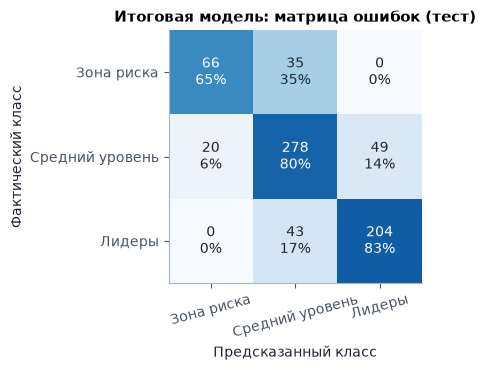

,точность,полнота,F1,объектов
Зона риска,0.767,0.653,0.706,101
Средний уровень,0.781,0.801,0.791,347
Лидеры,0.806,0.826,0.816,247


In [10]:
fig = plots.confusion_matrix(final["test"]["confusion_matrix"], CLASS_NAMES, "Итоговая модель: матрица ошибок (тест)"); plt.show()
pd.DataFrame({"точность": final["test"]["precision"], "полнота": final["test"]["recall"], "F1": final["test"]["f1"],
              "объектов": final["test"]["support"]}, index=CLASS_NAMES).round(3)

## 3.6. Сравнение с классическими моделями

In [11]:
remember("Случайный лес", pipeline.run_sklearn(prepared, "forest"))
table = remember("Градиентный бустинг", pipeline.run_sklearn(prepared, "boosting"))
table

,val: accuracy,val: macro_f1,val: macro_auc,val: log_loss,test: accuracy,test: macro_f1,test: macro_auc,test: log_loss
Наивный прогноз (класс не изменится),0.754,0.719,0.791,1.149,0.796,0.778,0.834,0.957
Softmax-регрессия на NumPy,0.723,0.682,0.871,0.665,0.738,0.724,0.888,0.630
Базовая сеть 64-32 (SGD),0.721,0.677,0.869,0.611,0.757,0.736,0.899,0.537
"Сеть 128-64 с регуляризацией, один выход",0.730,0.676,0.872,0.596,0.768,0.748,0.911,0.515
Многозадачная сеть 128-64,0.755,0.717,0.890,0.560,0.799,0.783,0.920,0.494
Ансамбль многозадачных сетей (model1.pt),0.766,0.721,0.894,0.546,0.788,0.771,0.923,0.476
Случайный лес,0.766,0.727,0.899,0.537,0.813,0.789,0.924,0.496
Градиентный бустинг,0.754,0.716,0.891,0.758,0.787,0.767,0.915,0.580


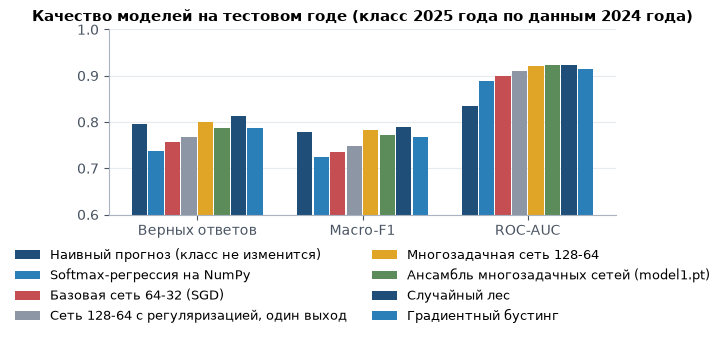

In [12]:
names = list(results)
plots.grouped_bars(["Верных ответов", "Macro-F1", "ROC-AUC"],
                   {name: [results[name]["test: accuracy"], results[name]["test: macro_f1"], results[name]["test: macro_auc"]] for name in names},
                   "Качество моделей на тестовом годе (класс 2025 года по данным 2024 года)"); plt.ylim(0.6, 1.0); plt.show()

**Выводы по качеству.**

* Улучшения архитектуры последовательно повышают качество сети: базовая сеть → регуляризация → многозадачность → ансамбль.
* По доле верных ответов лучшие модели находятся на уровне наивного прогноза (≈ 79–81 %): класс вуза очень инерционен,
  и это естественный потолок для годового прогноза. Требуемый уровень (не менее 70 %) превышен.
* По вероятностным метрикам модели **намного лучше** наивного прогноза: ROC-AUC ≈ 0,92 против 0,83, логарифмическая потеря
  ≈ 0,48 против 0,96. Модель умеет ранжировать организации по риску и указывает, какие из них близки к границе класса.

## 3.7. Какие признаки важны

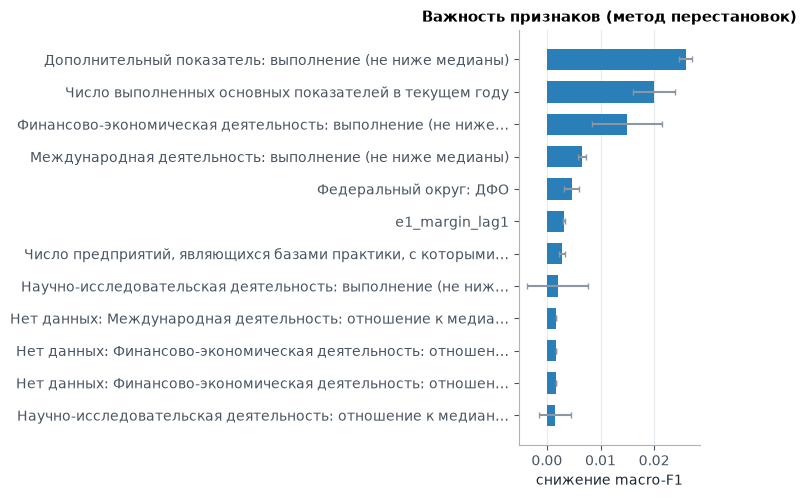

In [13]:
importance = explain.permutation_importance(predict, prepared.x["val"], prepared.y["val"], prepared.feature_names, n_repeats=3)[:12]
titles = dict(zip(frames["dictionary"]["column"], frames["dictionary"]["name"]))
plots.horizontal_bars([explain.feature_title(row["feature"], titles) for row in importance], [row["importance"] for row in importance],
                      "Важность признаков (метод перестановок)", "снижение macro-F1", errors=[row["std"] for row in importance]); plt.show()

## 3.8. Автокодировщик: профили и нетипичные организации

Вторая нейросетевая модель — шумоподавляющий автокодировщик (`models/model2.pt`). Он обучается без меток: сжимает
152 признака до 8 скрытых и восстанавливает исходный вектор; функция потерь — среднеквадратичная ошибка.
Большая ошибка восстановления означает необычное сочетание показателей.

MonitoringAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=152, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=24, bias=True)
    (4): BatchNorm1d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): Linear(in_features=24, out_features=8, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=8, out_features=24, bias=True)
    (1): BatchNorm1d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=24, out_features=64, bias=True)
    (4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=152, bias=True)
  )
)


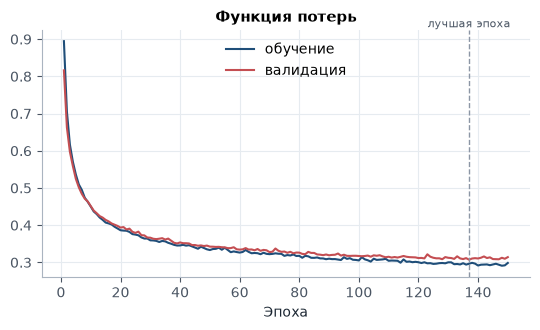

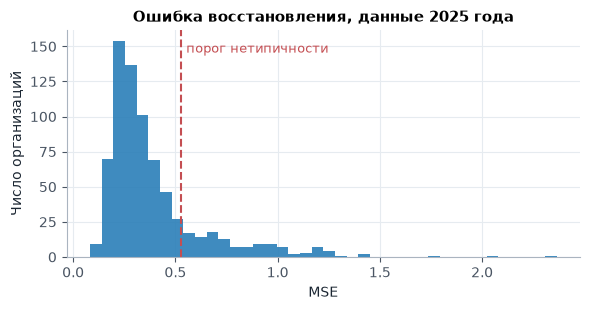

Нетипичных профилей: 128 из 736


,name,region,anomaly_score,cluster
706,Федеральное государственное бюджетное образова...,Херсонская область,2.364509,1
734,Автономная некоммерческая организация высшего ...,г.Москва,2.026104,4
705,Федеральное государственное бюджетное образова...,Херсонская область,1.742897,4
679,Автономная некоммерческая организация высшего ...,Челябинская область,1.421616,1
698,Федеральное государственное бюджетное образова...,Донецкая Народная Республика,1.400378,0
568,Частное образовательное учреждение высшего обр...,Приморский край,1.328086,1
724,Частное образовательное учреждение высшего обр...,Кабардино-Балкарская Республика,1.279685,1
723,Автономная некоммерческая организация высшего ...,г.Москва,1.275502,1


In [14]:
auto = registry.load_model(config.MODELS_DIR / "model2.pt")
print(auto.model)
plots.learning_curves(auto.meta["history"], auto.meta["metrics"]["best_epoch"]); plt.show()
profile = pipeline.profile(auto, prepared.parts["future"])
plots.histogram(profile["anomaly_score"], "Ошибка восстановления, данные 2025 года", "MSE", auto.meta["threshold"], "порог нетипичности"); plt.show()
print("Нетипичных профилей:", int(profile["is_anomaly"].sum()), "из", len(profile))
profile.sort_values("anomaly_score", ascending=False)[["name", "region", "anomaly_score", "cluster"]].head(8)

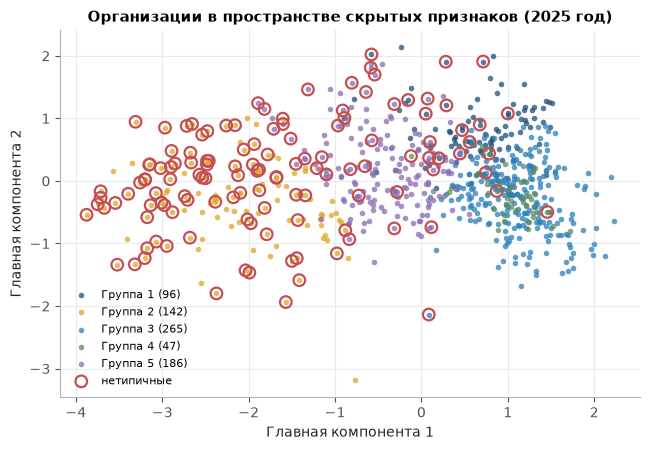

In [15]:
points = plots.pca_2d(profile[[c for c in profile.columns if c.startswith("z")]].to_numpy())
plots.scatter_map(points[:, 0], points[:, 1], profile["cluster"].to_numpy(), [f"Группа {i + 1}" for i in range(5)],
                  highlight=profile["is_anomaly"].to_numpy(), title="Организации в пространстве скрытых признаков (2025 год)",
                  xlabel="Главная компонента 1", ylabel="Главная компонента 2"); plt.show()

## 3.9. Сохранение, загрузка и применение модели

Модель сохраняется в файл вместе с предобработчиком и метриками; при загрузке сеть восстанавливается по описанию
архитектуры из файла. Ниже — проверка, что сохранённая и загруженная модели дают одинаковый ответ, и прогноз на 2026 год.

In [16]:
import tempfile
with tempfile.TemporaryDirectory() as folder:
    path = registry.save_classifier(Path(folder) / "model_copy.pt", multi_task["result"].model, prepared.preprocessor,
                                    multi_task["config"].to_dict(), {"test": multi_task["test"]}, CLASS_NAMES, multi_task["result"].history)
    copy = registry.load_model(path)
    same = np.allclose(trainer.predict_proba(copy.model, prepared.x["test"]), trainer.predict_proba(multi_task["result"].model, prepared.x["test"]))
    print("Размер файла, КБ:", round(path.stat().st_size / 1024), "| ответы совпадают:", same)

Размер файла, КБ: 131 | ответы совпадают: True


In [17]:
forecast = pipeline.forecast(loaded, prepared.parts["future"])
print("Прогноз на", int(forecast["target_year"].iloc[0]), "год для", len(forecast), "организаций:")
print(forecast["predicted_class"].map(dict(enumerate(CLASS_NAMES))).value_counts().to_string())
own = forecast[forecast["name"].str.contains("Витте")][["name", "current_class", "proba_0", "proba_1", "proba_2", "predicted_class"]]
own.round(3)

Прогноз на 2026 год для 736 организаций:
predicted_class
Средний уровень    367
Лидеры             252
Зона риска         117


,name,current_class,proba_0,proba_1,proba_2,predicted_class
482,Частное образовательное учреждение высшего обр...,1.0,0.072,0.909,0.019,1


## 3.10. Итоги

| Шаг | Что сделано | Результат на тесте |
|---|---|---|
| Опорная модель | softmax-регрессия на NumPy, градиентный спуск вручную | точка отсчёта |
| Базовая сеть | перцептрон 64–32, SGD | переобучение, хуже наивного прогноза |
| Улучшение 1 | нормализация, dropout, AdamW, ранняя остановка | качество выросло |
| Улучшение 2 | вспомогательная задача и структурная оценка класса | качество выросло |
| Улучшение 3 | подбор гиперпараметров и ансамбль из пяти сетей | итоговая модель `model1.pt` |

Точные значения метрик приведены в таблицах выше и в файле `models/metrics.json`.